# Customer Segmentation with Hierarchical Clustering

This notebook shows an original, deterministic hierarchical-clustering workflow. It uses synthetic customer features and standardizes them before fitting Ward linkage. The resulting dendrogram and cluster plot provide an interpretable segmentation view without any external data dependencies.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 43
OUTPUT_DIR = Path('generated/cluster-043'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
X, _ = make_blobs(n_samples=240, centers=4, cluster_std=1.2, random_state=SEED)
X_scaled = StandardScaler().fit_transform(X)
print('shape:', X_scaled.shape)

shape: (240, 2)


## 1. Build a Ward-linkage hierarchy

In [2]:
linked = linkage(X_scaled, method='ward')
clusters = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels = clusters.fit_predict(X_scaled)
print(f'ward silhouette: {silhouette_score(X_scaled, labels):.3f}')

ward silhouette: 0.707


## 2. Plot the dendrogram and the clustered points

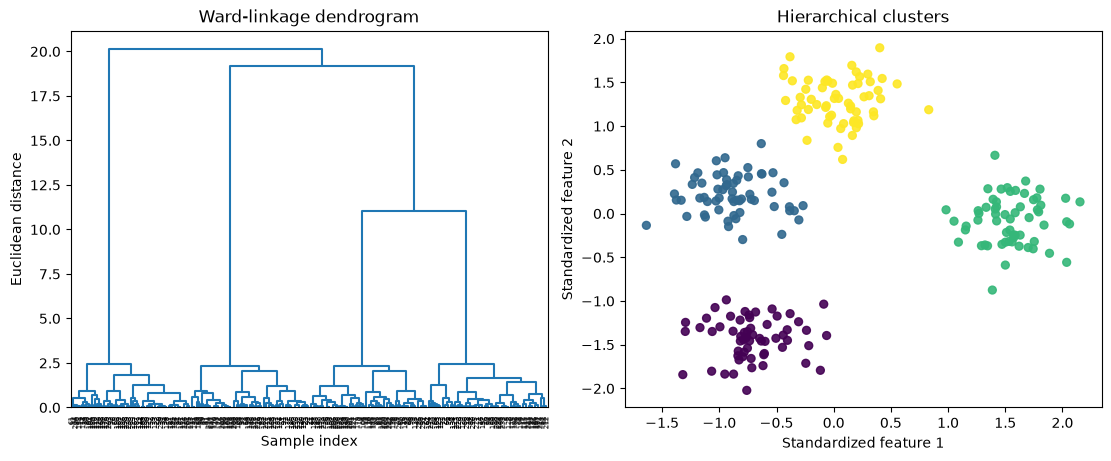

saved: generated\cluster-043\hierarchical-clustering.png


In [3]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
dendrogram(linked, ax=axes[0], color_threshold=0)
axes[0].set_title('Ward-linkage dendrogram'); axes[0].set_xlabel('Sample index'); axes[0].set_ylabel('Euclidean distance')
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis', s=32, alpha=0.9)
axes[1].set_title('Hierarchical clusters'); axes[1].set_xlabel('Standardized feature 1'); axes[1].set_ylabel('Standardized feature 2')
figure_path = OUTPUT_DIR / 'hierarchical-clustering.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show(); print('saved:', figure_path)